In [1]:
%reload_ext eradiate.tutorials

*Last updated: 2026-08-19 11:52 (eradiate v1.2.0)*

## Helper functions and imports

We start as for all tutorials with some imports and helper functions

In [2]:
import attrs
import matplotlib.pyplot as plt
import numpy as np

In [3]:
import eradiate

eradiate.set_mode("mono")

In [4]:
from eradiate.experiments import AtmosphereExperiment
from eradiate.grid import GridCoords, PlaneParallelGridCoords, SphericalShellGridCoords
from eradiate.scenes.atmosphere import ArrayParticleDistribution, ParticleEnsemble
from eradiate.scenes.geometry import (
    PlaneParallelGeometry,
    SphericalShellGeometry,
    WrapMode,
)
from eradiate.scenes.measure import PerspectiveCameraMeasure
from eradiate.units import unit_registry as ureg

In [5]:
resolution = 64

camera = PerspectiveCameraMeasure(
    id="camera",
    origin=[0, 0.01, 250] * ureg.km,
    target=[1, 0, 0],
    up=[0, 0, 1],
    film_resolution=(resolution, resolution),
    fov=0.2,
)


def plot_camera(res, vmax=None, ax=None):
    if ax is None:
        _, ax = plt.subplots(1, 1)
    res.squeeze(drop=True).plot.imshow(
        ax=ax,
        origin="upper",
        cmap="Greys_r",
        robust=True,
        add_colorbar=True,
        vmin=0,
        vmax=vmax,
    )
    ax.set_aspect(1)

## Geometry and grid definition

The default coordinate grid of Eradiate's atmosphere is a single dimension, z-axis aligned regular grid. This discretization is only suitable for 1D atmospheres.

In [6]:
z_grid = GridCoords.make_default()
z_grid

axis,extent,cells
x (width),-5e+05 km … 5×10⁵ km,1
y (length),-5e+05 km … 5×10⁵ km,1
z (altitude),0 m … 1.2×10⁵ m,1200


The diagram of the grid is not at scale. This representation only helps vizualising the mapping from the grid dimension to the scene 3D space (i.e. the effect of the grid `to_world` transform).

In [7]:
z_grid.to_world

Transform[
  matrix=[[1e+09, 0, 0, -5e+08],
          [0, 1e+09, 0, -5e+08],
          [0, 0, 120000, 0],
          [0, 0, 0, 1]],
  inverse_transpose=[[1e-09, 0, 0, 0],
                     [0, 1e-09, 0, 0],
                     [0, 0, 8.33333e-06, 0],
                     [0.5, 0.5, 0, 1]]
]

It is possible to generate different regular discretizations in the x and y axes, for instance: 

In [8]:
# Split the current grid x and y axes into fixed cells of 50m
grid_test = z_grid.resampled_to_cell_size(50 * ureg.m, 50 * ureg.m)
# Crop the (x, y) grid into a centered rectangle of 200m by 300m
grid_test = grid_test.cropped(200 * ureg.m, 300 * ureg.m)
grid_test

axis,extent,cells
x (width),-0.1 km … 0.1 km,4
y (length),-0.15 km … 0.15 km,6
z (altitude),0 m … 1.2×10⁵ m,1200


The constructor of PlaneParallelGridCoords also accepts x and y edges as a parametrization.

In [9]:
grid_3d = PlaneParallelGridCoords(
    levels=np.linspace(0, 200, 201) * ureg.m,
    edges_x=np.linspace(0, 200, 5) * ureg.m,
    edges_y=np.linspace(0, 300, 7) * ureg.m,
).centered()
grid_3d

axis,extent,cells
x (width),-100 m … 100 m,4
y (length),-150 m … 150 m,6
z (altitude),0 m … 200 m,200


Similarly, a 3D grid can be collapsed into a 1D vertical grid, keeping the extents in x and y.

In [10]:
grid_3d.single_column()

axis,extent,cells
x (width),-100 m … 100 m,1
y (length),-150 m … 150 m,1
z (altitude),0 m … 200 m,200


Geometries generate the mitsuba shape of the atmospheric medium where the properties defined on our coordinate grid are sampled. Geometries accept a coordinate grid.

In [11]:
geometry_3d = PlaneParallelGeometry(grid=grid_3d)
geometry_3d

PlaneParallelGeometry(toa_altitude=200.0 m, ground_altitude=0.0 m, grid=PlaneParallelGridCoords(
  x: [-100.0 m, 100.0 m], 4 cells
  y: [-150.0 m, 150.0 m], 6 cells
  z: [0.0 m, 200.0 m], 200 layers
), filter_type=<FilterType.NEAREST: 1>, wrap_mode=<WrapMode.CLAMP: 0>, width=1000000.0 km)

This diagram has a logarithmic scale.

In [12]:
geometry_3d.width

<Quantity(1000000.0, 'kilometer')>

In this example, the shape width is 10^6 km, much larger than our grid extent of 200m by 300m where our (4, 6, 100) shaped properties are defined. We will later see how the missing data is extrapolated using the `WrapMode`.

Spherical shell grids are supported, but their X and Y coordinates are expressed in angular units, to map to a spherical shell geometry.

In [13]:
sph_grid = SphericalShellGridCoords(
    levels=np.linspace(0, 100, 101) * ureg.meter,
    azimuths=np.linspace(175, 185, 11) * ureg.degree,
    colatitudes=np.linspace(85, 95, 11) * ureg.degree,
)
sph_grid

axis,extent,cells
azimuth,175 deg … 185 deg,10
colatitude,85 deg … 95 deg,10
z (altitude),0 m … 100 m,100


## Particle ensemble of varying AOT

Now we are defining a set of particles of varying AOT $\tau_{ref}$ indexed on the 3D grid. These particles vary within the grid in geometry and optical thickness, but keep the same phase function.

We define a checkerboard of different $\tau_{ref}$ values to map on the X and Y coordinates of the grid. The maximum $\tau_{ref}$ of this grid is 5 [unitless].

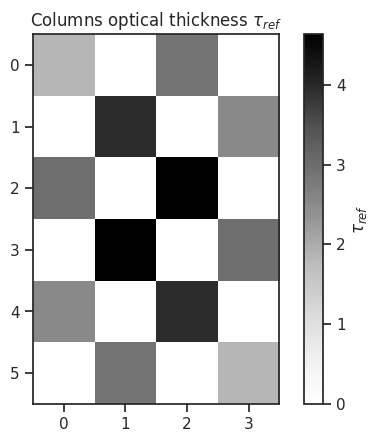

In [14]:
tau_max = 5

x, y = np.meshgrid(np.linspace(-1, 1, 4), np.linspace(-1, 1, 6))
d = np.sqrt(x * x + y * y)
sigma, mu = 1.0, 0.0
g = np.exp(-((d - mu) ** 2 / (2.0 * sigma**2)))
tau_ref = np.ones((4, 6))
tau_ref *= g.T
tau_ref = tau_ref * tau_max

i = np.repeat(np.arange(tau_ref.shape[0]).reshape(1, -1), tau_ref.shape[1], axis=0)
j = np.repeat(np.arange(tau_ref.shape[1]).reshape(-1, 1), tau_ref.shape[0], axis=1)
mask = i % 2 == j % 2
tau_ref = np.where(mask.T, tau_ref, 0)

cbar = plt.colorbar(plt.imshow(tau_ref.T, cmap="Greys"), label="$\\tau_{ref}$")
plt.title("Columns optical thickness $\\tau_{ref}$")
plt.show()
plt.close()

The default particle vertical distribution is uniform. The particle ensemble accepts the 2D $\tau_{ref}$ array, and applies it the X and Y coordinates of the grid, in that order. Each column's particle distribution is then rescaled according to the corresponding $\tau_{ref}(x, y)$.

In [15]:
particles_tau2d = ParticleEnsemble(
    geometry=geometry_3d, tau_ref=tau_ref, bottom=0, top=20 * ureg.m
)

We wire this to a scene a perform a simulation

In [16]:
exp = AtmosphereExperiment(
    atmosphere=particles_tau2d,
    surface={"type": "lambertian", "reflectance": 0.8},
    measures=camera,
    illumination={"type": "directional", "zenith": 30, "azimuth": 30},
    integrator={"type": "eovolpath"},
    geometry=geometry_3d,
)

In [17]:
%%time
res = eradiate.run(exp, spp=1000)

CPU times: user 4min 30s, sys: 80.7 ms, total: 4min 30s
Wall time: 14.9 s


Text(0, 0.5, 'length pixel index')

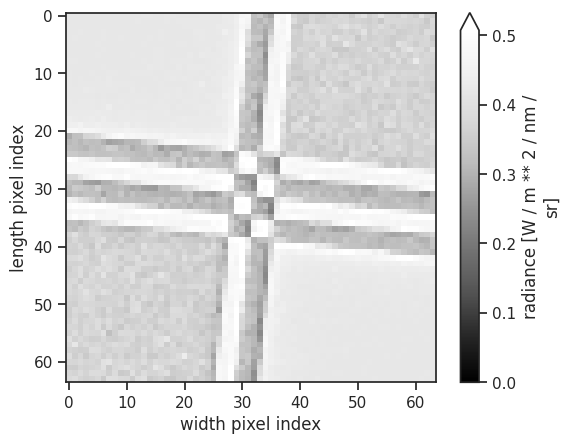

In [18]:
plot_camera(res.radiance)
plt.ylabel("length pixel index")

## Wrap mode

So far, we have used the `WrapMode` to extrapolate properties outside the grid horizontal extents but we have not configured it. By default, the extent of the geometry's shape that is not covered by the grid in the x and y axes is handled by `WrapMode.CLAMP`. All interaction positions outside the grid and inside the atmosphere's shape is clamped to the grid boundary. The resulting effect it the extension of the last grid cells towards the full atmospheric shape extent.

`WrapMode.REPEAT` repeats the pattern of the atmospheric properties and `WrapMode.MIRROR` performs a symmetry:

In [19]:
exp_repeat = AtmosphereExperiment(
    atmosphere=particles_tau2d,
    surface={"type": "lambertian", "reflectance": 0.8},
    measures=camera,
    integrator={"type": "volpath", "moment": True},
    geometry=attrs.evolve(geometry_3d, wrap_mode=WrapMode.REPEAT),
    illumination={"type": "directional", "zenith": 30, "azimuth": 30},
)

exp_mirror = AtmosphereExperiment(
    atmosphere=particles_tau2d,
    surface={"type": "lambertian", "reflectance": 0.8},
    measures=camera,
    integrator={"type": "volpath", "moment": True},
    geometry=attrs.evolve(geometry_3d, wrap_mode=WrapMode.MIRROR),
    illumination={"type": "directional", "zenith": 30, "azimuth": 30},
)

In [20]:
%%time
res_repeat = eradiate.run(exp_repeat, spp=1000)
res_mirror = eradiate.run(exp_mirror, spp=1000)

CPU times: user 10min 1s, sys: 127 ms, total: 10min 1s
Wall time: 30.2 s


Text(0.5, 1.0, 'WrapMode.MIRROR')

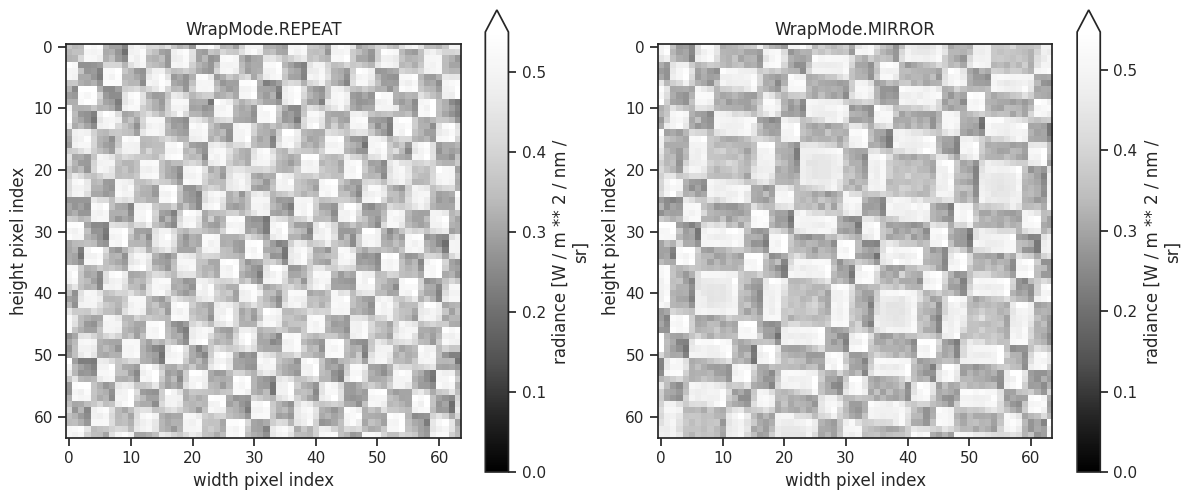

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
plot_camera(res_repeat.radiance, ax=ax1)
ax1.set_title("WrapMode.REPEAT")
plot_camera(res_mirror.radiance, ax=ax2)
ax2.set_title("WrapMode.MIRROR")

## Altitude and height variations

This time we apply a variation of the ensemble's vertical extent, defined by its bottom and top altitudes at the different grid X and Y cells. Here we define arbitrary extents, in the form of X and Y aligned steps

In [22]:
# Define voxels geometries using in the form of 20m high steps
bottom = (
    np.asarray([[20.0 * float(i_x + i_y) for i_y in range(6)] for i_x in range(4)])
    * ureg.m
)
top = bottom + 20.0 * ureg.m

In [23]:
mirror_geom = attrs.evolve(geometry_3d, wrap_mode=WrapMode.MIRROR)

particles_h2d = ParticleEnsemble(
    geometry=mirror_geom,
    tau_ref=0.5,
    bottom=bottom,
    top=top,
)

exp_alt = AtmosphereExperiment(
    atmosphere=particles_h2d,
    surface={"type": "lambertian", "reflectance": 0.8},
    measures=camera,
    illumination={"type": "directional", "zenith": 30, "azimuth": 45},
    integrator={"type": "eovolpath"},
    geometry=mirror_geom,
)

In [24]:
%%time
res_alt = eradiate.run(exp_alt, spp=1000)

CPU times: user 48.7 s, sys: 7.92 ms, total: 48.7 s
Wall time: 2.39 s


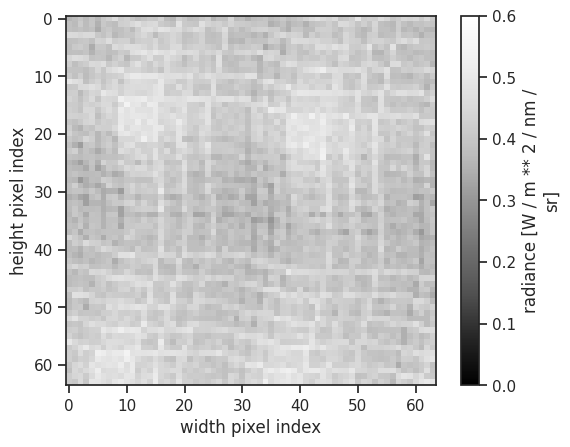

In [25]:
plot_camera(res_alt.radiance, vmax=0.6)

## Vertical distributions

The third entrypoint for particles spatial variations is the vertical distribution. `ArrayParticleDistribution` also accepts a 3D `values` array, shaped (n_x, n_y, n_z). This array defines an independent vertical distribution at each (i_x, i_y) position.

In [26]:
n_x, n_y = 4, 6
n_z = n_x * n_y
rng = np.random.default_rng(0)
peak = rng.permutation(n_z).reshape(n_x, n_y)  # randomize location of each column

values_3d = np.zeros((n_x, n_y, n_z))
np.put_along_axis(values_3d, peak[..., None], 1.0, axis=-1)

dist_3d = ArrayParticleDistribution(values=values_3d, method="linear")

z = np.broadcast_to(np.linspace(0, 1, 50), (n_x, n_y, 50))
profile = dist_3d(z)

In [35]:
particles_dist3d = ParticleEnsemble(
    geometry=mirror_geom,
    tau_ref=0.5,
    bottom=0,  # np.zeros((4, 6)) * ureg.m,
    top=30 * ureg.m,  # np.full((4, 6), 30) * ureg.m,
    distribution=dist_3d,
)

In [36]:
exp_dist3d = AtmosphereExperiment(
    atmosphere=particles_dist3d,
    surface={"type": "lambertian", "reflectance": 0.8},
    measures=camera,
    illumination={"type": "directional", "zenith": 30, "azimuth": 45},
    integrator={"type": "eovolpath"},
    geometry=mirror_geom,
)

In [37]:
%%time
res_dist3d = eradiate.run(exp_dist3d, spp=1000)

CPU times: user 6min 48s, sys: 94.6 ms, total: 6min 48s
Wall time: 20.5 s


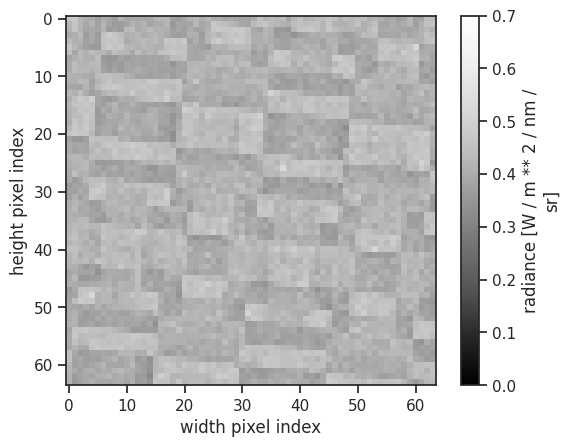

In [30]:
plot_camera(res_dist3d.radiance, vmax=0.7)

## Spherical shell support

We briefly mentioned spherical shell geometries support but did not exercise it. For this we define another $\tau_{ref}$ arbitrary shape

For this example we will use a sizeable grid compared to the default Earth-sized sphere used by default in Eradiate, expressed in `(altitude, azimuths, colatitudes)`.

In [31]:
sph_grid = SphericalShellGridCoords(
    levels=np.linspace(0, 200, 201),
    azimuths=np.linspace(-20, 20, 13) * ureg.degree,
    colatitudes=np.linspace(70, 110, 13) * ureg.degree,
)
sph_geom = SphericalShellGeometry(
    grid=sph_grid,
    wrap_mode=WrapMode.CLAMP,
)
sph_geom

SphericalShellGeometry(toa_altitude=200.0 m, ground_altitude=0.0 m, grid=SphericalShellGridCoords(
  azimuth:    [-20.0 deg, 20.0 deg], 12 sectors
  colatitude: [70.0 deg, 110.0 deg], 12 bands
  z:          [0.0 m, 200.0 m], 200 layers
), filter_type=<FilterType.NEAREST: 1>, wrap_mode=<WrapMode.CLAMP: 0>, planet_radius=6378.1 km)

In [32]:
# We define a circle shaped particles plume
sph_tau_ref = np.asarray(
    [
        [(i_x + 0.5) ** 2 + (i_y + 0.5) ** 2 for i_y in range(-6, 6)]
        for i_x in range(-6, 6)
    ]
)
sph_tau_ref = (sph_tau_ref < 5.1**2).astype(float) * 2.0

particles_sph = ParticleEnsemble(
    geometry=sph_geom,
    tau_ref=sph_tau_ref,
    bottom=60 * ureg.m,
    top=80 * ureg.m,
)

In [33]:
%%time

d = 10 * sph_geom.planet_radius.m_as("km")

sph_camera = PerspectiveCameraMeasure(
    id="camera",
    origin=[d, 0, 0] * ureg.km,
    target=[0, 0, 0],
    up=[0, 0, 1],
    film_resolution=(32, 32),
    fov=14,
    far_clip=2 * d * ureg.km,  # We are observing the entire Earth-sized sphere
    # thus we need a larger far_clip value than the default 10^4 km
)

exp_sph = AtmosphereExperiment(
    atmosphere=particles_sph,
    surface={"type": "lambertian", "reflectance": 0.8},
    measures=sph_camera,
    illumination={"type": "directional", "zenith": 60, "azimuth": 0},
    integrator={"type": "eovolpath"},
    geometry=sph_geom,
)

res_sph = eradiate.run(exp_sph, spp=1000)

CPU times: user 12min 2s, sys: 142 ms, total: 12min 2s
Wall time: 2min 38s


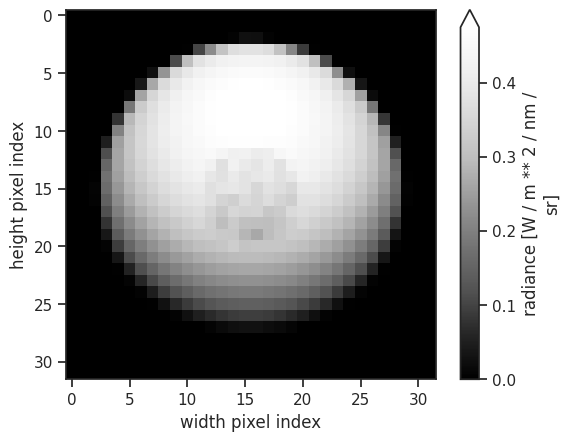

In [34]:
plot_camera(res_sph.radiance)